# Exploratory Data Analysis — Credit Card Fraud Detection
**CO7201 MSc Computing — Week 1**

Dataset: Kaggle Credit Card Fraud Detection (284,807 transactions, 492 fraud cases)  
Features: V1–V28 (PCA-anonymised), Time, Amount, Class (0=genuine, 1=fraud)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/creditcard.csv")
print(df.shape)

(284807, 31)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
# check for nulls
print(df.isnull().sum().sum(), "missing values")

0 missing values


In [5]:
# class distribution
counts = df["Class"].value_counts()
fraud_pct = counts[1] / len(df) * 100
print(f"Genuine: {counts[0]:,}  |  Fraud: {counts[1]:,}  |  Fraud rate: {fraud_pct:.4f}%")

Genuine: 284,315  |  Fraud: 492  |  Fraud rate: 0.1727%


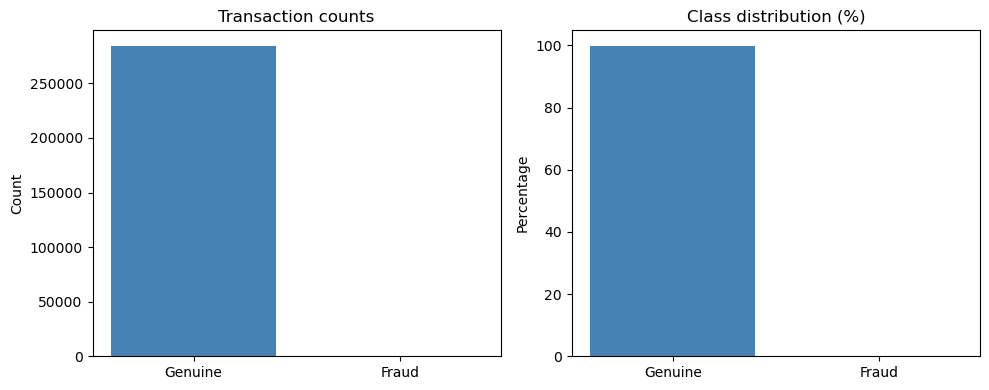

In [6]:
# plot class imbalance
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(["Genuine", "Fraud"], [counts[0], counts[1]], color=["steelblue", "crimson"])
axes[0].set_title("Transaction counts")
axes[0].set_ylabel("Count")

axes[1].bar(["Genuine", "Fraud"], [100 - fraud_pct, fraud_pct], color=["steelblue", "crimson"])
axes[1].set_title("Class distribution (%)")
axes[1].set_ylabel("Percentage")

plt.tight_layout()
plt.savefig("../notebooks/class_imbalance.png", dpi=150)
plt.show()

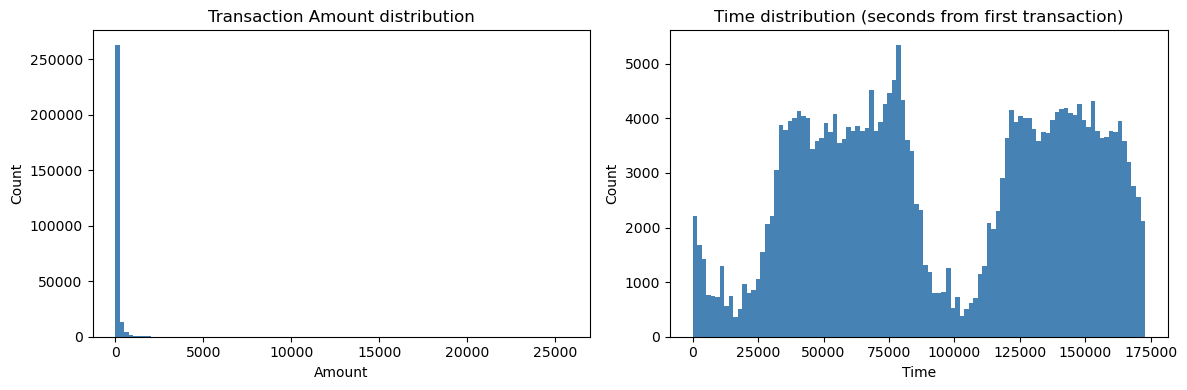

In [7]:
# Amount and Time distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Amount"], bins=100, color="steelblue", edgecolor="none")
axes[0].set_title("Transaction Amount distribution")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Count")

axes[1].hist(df["Time"], bins=100, color="steelblue", edgecolor="none")
axes[1].set_title("Time distribution (seconds from first transaction)")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("../notebooks/amount_time_dist.png", dpi=150)
plt.show()

In [8]:
# Amount statistics split by class
df.groupby("Class")["Amount"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [9]:
# correlation of V features with Class (top 10 by absolute value)
corr = df.corr()["Class"].drop("Class").abs().sort_values(ascending=False)
print(corr.head(10))

V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64
